Importo las librerias que voy a usar


In [40]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import convolve2d

Funcion para cargar imagen

In [22]:
def cargarImagen(ruta):
  return cv2.imread(ruta,cv2.IMREAD_GRAYSCALE)

Funcion cargar imagen

In [23]:
def mostrar_imagen(imagen,titulo):
  plt.imshow(imagen,cmap='gray')
  #plt.axis('off')
  plt.title(titulo)

Funcion que hace downsampling

In [24]:
def downsamplingX2(img):
    img_proc=img[::2,::2]
    return img_proc

Funcion que hace downsampling promedio

In [42]:
"""
def dowmsamplingX2_promedio(img):
    ancho,alto=img.shape
    img_nueva=np.zeros(shape=(alto//2,ancho//2)) # creo una imagen nueva

    for y in range(alto//2):
        for x in range(ancho//2):
            promedio= np.mean(img[2*y:2*y+2,2*x:2*x+2]) # el mean calcula el promedio
            img_nueva[y,x] =promedio
    return img_nueva

"""
def downsampling_x2_promedio(img):

    if img is None:
        return None
    h, w = img.shape
    h2 = h // 2
    w2 = w // 2

    img_cropped = img[:h2*2, :w2*2].astype(np.float32)
    img_blocks = img_cropped.reshape(h2, 2, w2, 2)
    img_mean = img_blocks.mean(axis=(1, 3))
    if img.dtype == np.uint8:
        return np.round(img_mean).astype(np.uint8)
    else:
        return img_mean.astype(img.dtype)

Funcion que hace upsampling

In [26]:
"""
def upsamplingx2(img):
    ancho,alto=img.shape
    img_nueva=np.zeros(shape=(alto*2,ancho*2))

    for i in range(0,alto*2,2):
        for j in range(0,ancho*2,2):
           img_nueva[i:i+2, j:j+2]=img[i//2,j//2]

    return img_nueva
"""

def upsamplingx2(img):
    h, w = img.shape                           # alto, ancho
    img_nueva = np.zeros((h*2, w*2))           # imagen ampliada

    for i in range(0, h*2, 2):                 # i = 0,2,4,...
        for j in range(0, w*2, 2):             # j = 0,2,4,...
            img_nueva[i:i+2, j:j+2] = img[i//2, j//2]

    return img_nueva

In [36]:
def upsamplingx2_promedio(img):
    h, w = img.shape
    img_nueva = np.zeros((h*2, w*2))

    for i in range(h):
        for j in range(w):
            i0 = max(0, i-1)
            j0 = max(0, j-1)
            i1 = min(h, i+2)
            j1 = min(w, j+2)
            promedio = np.mean(img[i0:i1, j0:j1])
            img_nueva[2*i:2*i+2, 2*j:2*j+2] = promedio

    return img_nueva

In [38]:
def upsampingx2_bilineal(img):
    kernel=np.array([[1/4,1/2,1/4],[1/2,1,1/2],[1/4,1/2,1/4]])
    kernel=kernel / kernel.sum()

    alto=img.shape[0]
    ancho=img.shape[1]
    img_proc = np.zeros(shape=(alto*2,ancho*2))
    img_proc[::2,::2] = img
    img_proc=convolve2d(img_proc,kernel,mode='full',boundary='symm')
    return img_proc


def upsampingx2_bicubica(img):
    vector_1 = np.array([-1/8,0,5/8,1,5/8,0,-1/8])
    vector_2 = np.array([-1/8,0],[5/8],[1],[5/8],[0],[-1/8]])

    kernel=np.outer(vector_1,vector_2)
    kernel=kernel / kernel.sum()

    alto=img.shape[0]
    ancho=img.shape[1]
    img_proc = np.zeros(shape=(alto*2,ancho*2))
    img_proc[::2,::2] = img
    img_proc=convolve2d(img_proc,kernel,mode='full',boundary='symm')
    return img_proc

In [28]:
def scanLine(imagen, niveles):
    # Convertir a float para poder acumular error
    img = imagen.astype(float)
    maximo = 255
    minimo = 0
    rango = maximo - minimo
    delta = rango/niveles
    listaNiveles = np.linspace(minimo,maximo,num= niveles)
    listaCortes = np.arange(delta/2, maximo - delta/2, delta)

    alto, ancho = img.shape

    for y in range(alto):
        for x in range(ancho):

            pixelOriginal = img[y, x]

            # Cuantización usando digitize
            indice = np.digitize(pixelOriginal, listaCortes) # este indice me va a apuntar en que nivel estoy dentro de la lista de niveles
            pixelCuantizado = listaNiveles[indice]

            # Reemplazar valor
            img[y, x] = pixelCuantizado

            # Error
            error = pixelOriginal - pixelCuantizado

            # Difusión del error (Floyd–Steinberg)
            if x+1 < ancho:
                img[y, x+1] += error * (7/16)
            if y+1 < alto and x > 0:
                img[y+1, x-1] += error * (3/16)
            if y+1 < alto:
                img[y+1, x] += error * (5/16)
            if y+1 < alto and x+1 < ancho:
                img[y+1, x+1] += error * (1/16)

    return img.clip(0, 255).astype(np.uint8)

In [29]:
def cuantizaionUniforme(imagen, niveles):
    maximo = 255
    minimo = 0
    rango = maximo - minimo
    delta = rango/niveles
    listaNiveles = np.linspace(minimo,maximo,num= niveles)
    listaCortes = np.arange(delta/2, maximo - delta/2, delta)
    indices = np.digitize(imagen, listaCortes)
    imagenResultante = listaNiveles[indices].astype(np.uint8)
    return imagenResultante

Comienzo a mostrar las imagenes

In [30]:
img=cargarImagen('imagen1.jpg')
img_procesada=downsamplingX2(img)
img_procesada2=downsampling_x2_promedio(img)

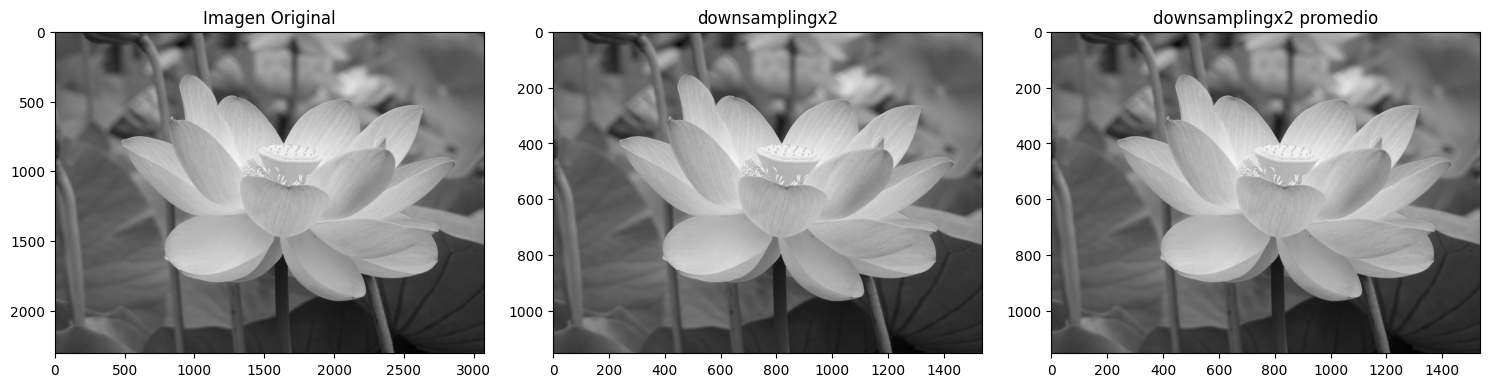

In [31]:
fila=1
columna=3
plt.figure(figsize=(15,15))

plt.subplot(fila,columna,1)
mostrar_imagen(img,'Imagen Original')

plt.subplot(fila,columna,2)
mostrar_imagen(img_procesada,'downsamplingx2')


plt.subplot(fila,columna,3)
mostrar_imagen(img_procesada2,'downsamplingx2 promedio')

plt.tight_layout()

In [32]:
img_procesada3=upsamplingx2(img)
img_procesada4=upsamplingx2_promedio(img)

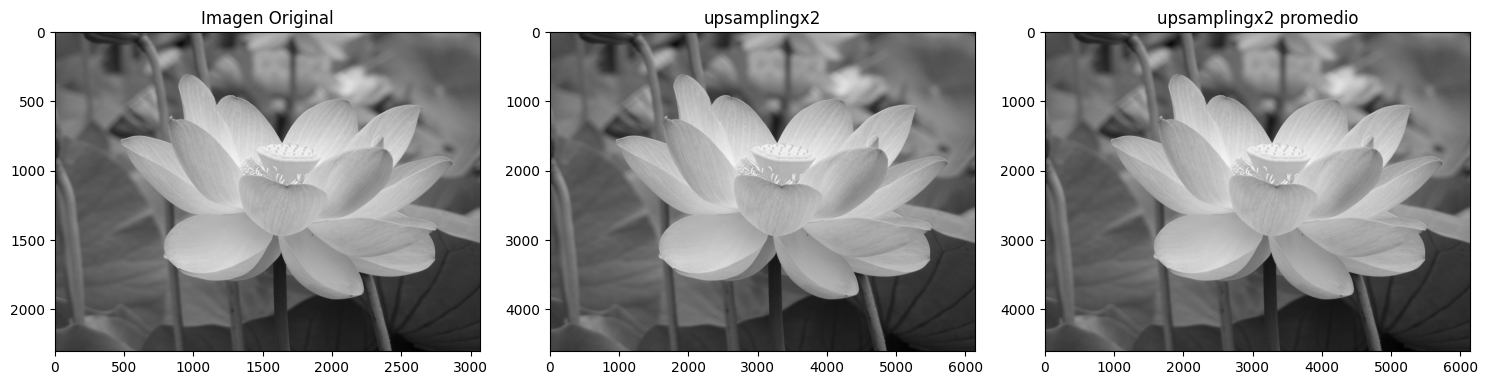

In [33]:
plt.figure(figsize=(15,15))

plt.subplot(fila,columna,1)
mostrar_imagen(img,'Imagen Original')

plt.subplot(fila,columna,2)
mostrar_imagen(img_procesada3,'upsamplingx2')


plt.subplot(fila,columna,3)
mostrar_imagen(img_procesada4,'upsamplingx2 promedio')

plt.tight_layout()

In [34]:
img_procesada5=scanLine(img,10)
img_procesada6=cuantizaionUniforme(img,10)

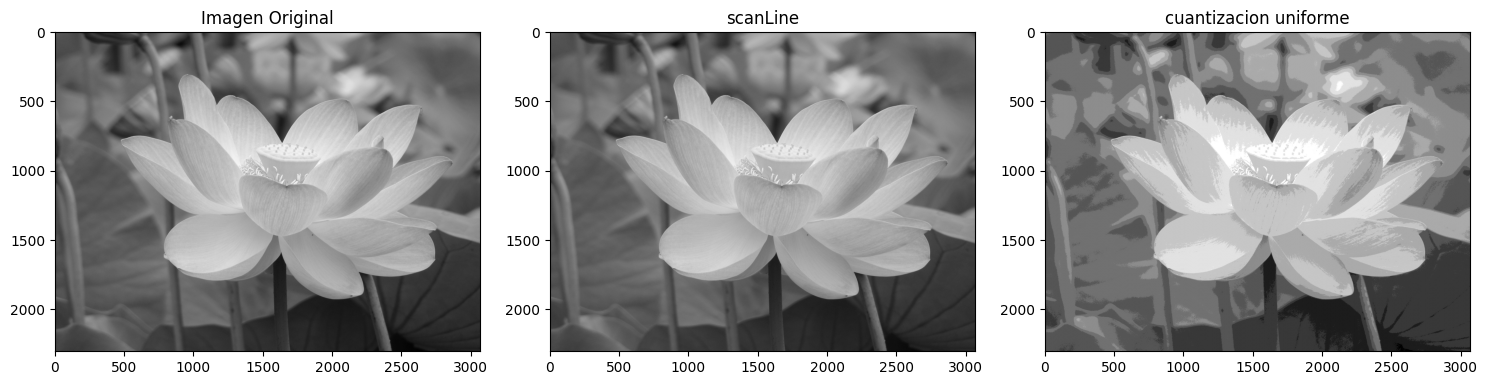

In [35]:
plt.figure(figsize=(15,15))

plt.subplot(fila,columna,1)
mostrar_imagen(img,'Imagen Original')

plt.subplot(fila,columna,2)
mostrar_imagen(img_procesada5,'scanLine')


plt.subplot(fila,columna,3)
mostrar_imagen(img_procesada6,'cuantizacion uniforme')

plt.tight_layout()

In [43]:
img_procesada7=upsampingx2_bilineal(img)
img_procesada8=upsampingx2_bicubica(img)

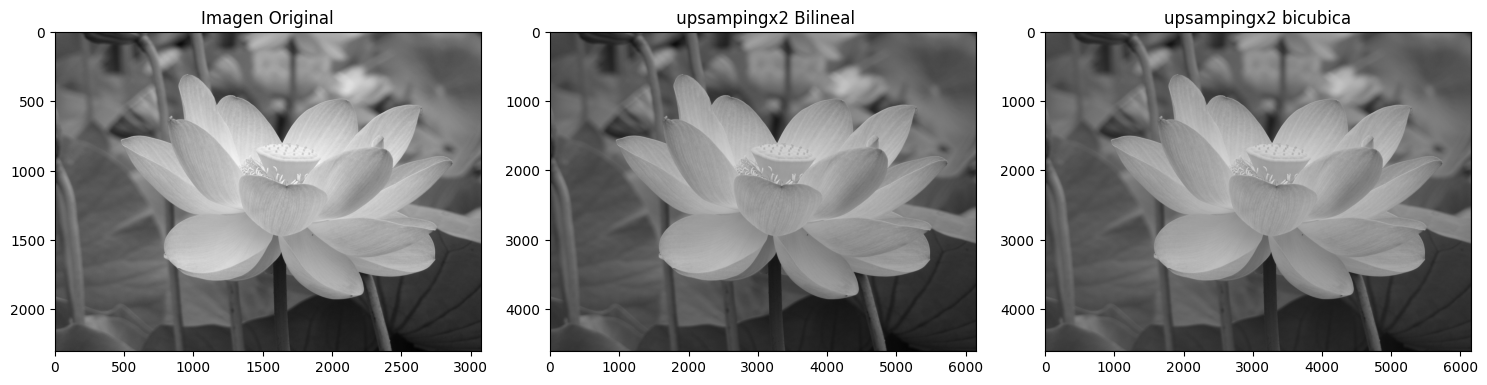

In [45]:
plt.figure(figsize=(15,15))

plt.subplot(fila,columna,1)
mostrar_imagen(img,'Imagen Original')

plt.subplot(fila,columna,2)
mostrar_imagen(img_procesada7,' upsampingx2 Bilineal')


plt.subplot(fila,columna,3)
mostrar_imagen(img_procesada8,'upsampingx2 bicubica')

plt.tight_layout()